# MIT 18.06 Linear Algebra - Lecture 3 Notes (Part 2)
**Instructor:** Prof. Gilbert Strang  
**Lecture Video:** [3. Multiplication and Inverse Matrices](https://youtu.be/FX4C-JpTFgY) (Covering 21:44 to End)

---

## Table of Contents
1. [Foundational Definitions: Inverses of Square Matrices](#1-foundational-definitions-inverses-of-square-matrices)
2. [The Singular Case (Non-Invertible Matrices)](#2-the-singular-case-non-invertible-matrices)
3. [The Invertible Case (Non-Singular Matrices)](#3-the-invertible-case-non-singular-matrices)
4. [Gauss-Jordan Elimination: Solving Multiple Systems Simultaneously](#4-gauss-jordan-elimination-solving-multiple-systems-simultaneously)
5. [Comprehensive Python Visualizations and Computational Verification](#5-comprehensive-python-visualizations-and-computational-verification)


---
## 1. Foundational Definitions: Inverses of Square Matrices

Let $A$ be a square $n \times n$ matrix. If there exists an $n \times n$ matrix $A^{-1}$ such that:

$$
A^{-1}A = I = A A^{-1}
$$

where $I$ is the $n \times n$ identity matrix, then $A$ is termed **invertible** or **non-singular**.

> **Key Note on Left vs. Right Inverses:**  
> In the equation above, $A^{-1}A = I$ identifies $A^{-1}$ as a **left inverse**, while $A A^{-1} = I$ identifies it as a **right inverse**.  
> For finite-dimensional square matrices ($n \times n$), a fundamental theorem of linear algebra states that if a matrix possesses a left inverse, that same matrix is necessarily its right inverse ($A^{-1}A = I \iff A A^{-1} = I$). For non-square rectangular matrices ($m \times n$ where $m \neq n$), left and right inverses diverge.

---
## 2. The Singular Case (Non-Invertible Matrices)

Consider the $2 \times 2$ matrix from the handwritten notes and lecture:

$$
A = \begin{pmatrix} 1 & 3 \\ 2 & 6 \end{pmatrix}
$$

This matrix is **singular** (it has no inverse). There are two complementary viewpoints to understand why an inverse cannot exist.

### Geometric Perspective: Collinear Column Vectors and the Line $y = 2x$
Let the column vectors of $A$ be denoted by $\mathbf{v}_1$ and $\mathbf{v}_2$:

$$
\mathbf{v}_1 = \begin{pmatrix} 1 \\ 2 \end{pmatrix}, \quad \mathbf{v}_2 = \begin{pmatrix} 3 \\ 6 \end{pmatrix} = 3\begin{pmatrix} 1 \\ 2 \end{pmatrix}
$$

Notice the relationship between the x-component and y-component of these vectors:
- For $\mathbf{v}_1 = \begin{pmatrix} x \\ y \end{pmatrix} = \begin{pmatrix} 1 \\ 2 \end{pmatrix}$, we have $y = 2(1) = 2x$.
- For $\mathbf{v}_2 = \begin{pmatrix} x \\ y \end{pmatrix} = \begin{pmatrix} 3 \\ 6 \end{pmatrix}$, we have $y = 2(3) = 6 = 2x$.

Both column vectors lie perfectly on the straight line given by the equation **$y = 2x$**.

When multiplying $A$ by any arbitrary matrix $B$, the resulting columns are linear combinations of the columns of $A$:

$$
A B = A \begin{pmatrix} \mathbf{b}_1 & \mathbf{b}_2 \end{pmatrix} = \begin{pmatrix} A\mathbf{b}_1 & A\mathbf{b}_2 \end{pmatrix}
$$

Because any combination $c_1 \begin{pmatrix} 1 \\ 2 \end{pmatrix} + c_2 \begin{pmatrix} 3 \\ 6 \end{pmatrix} = (c_1 + 3c_2)\begin{pmatrix} 1 \\ 2 \end{pmatrix}$ results in a vector where the second component is always exactly twice the first component, the entire output space is restricted to the line $y = 2x$.

It is therefore geometrically impossible for $A B$ to ever produce the standard basis vectors of the identity matrix $I = \begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix}$. Specifically, the vector $\begin{pmatrix} 1 \\ 0 \end{pmatrix}$ does not lie on the line $y = 2x$ (since $0 \neq 2(1)$).

> **Rank 1 Matrix:**  
> The matrix $A = \begin{pmatrix} 1 & 3 \\ 2 & 6 \end{pmatrix}$ has only 1 linearly independent column (and 1 linearly independent row). Its column space is 1-dimensional (a line). Hence, $\operatorname{rank}(A) = 1 < 2$, making it rank-deficient and singular.

### Algebraic Perspective: Non-Trivial Nullspace Solutions ($A\mathbf{x}=\mathbf{0}$)
A square matrix $A$ is singular if and only if there exists a non-zero vector $\mathbf{x} \neq \mathbf{0}$ such that:

$$
A\mathbf{x} = \mathbf{0}
$$

Let $\mathbf{x} = \begin{pmatrix} a \\ b \end{pmatrix}$. Then:

$$
\begin{pmatrix} 1 & 3 \\ 2 & 6 \end{pmatrix} \begin{pmatrix} a \\ b \end{pmatrix} = \begin{pmatrix} 0 \\ 0 \end{pmatrix}
$$

Expressed as a linear combination of columns:

$$
a \begin{pmatrix} 1 \\ 2 \end{pmatrix} + b \begin{pmatrix} 3 \\ 6 \end{pmatrix} = \begin{pmatrix} 0 \\ 0 \end{pmatrix}
$$

This yields the scalar system:
$$
\begin{aligned}
\text{(i)} \quad & a + 3b = 0 \\
\text{(ii)} \quad & 2a + 6b = 0
\end{aligned}
$$

### Detailed Derivation & Free Variable Analysis
Performing row elimination on equation (ii) using equation (i):

$$
\text{(ii)}' = \frac{1}{2}\text{(ii)} - \text{(i)}:
$$
$$
\begin{aligned}
(a + 3b) - (a + 3b) &= 0 \\
0 &= 0
\end{aligned}
$$

Thus, the second equation is redundant ($0=0$), leaving the single constraint:

$$
a + 3b = 0 \implies a = -3b
$$

Here, $b$ is a **free variable**, which can assume infinitely many values:
- If $b = 0$, then $a = 0 \implies \mathbf{x} = \begin{pmatrix} 0 \\ 0 \end{pmatrix}$ (the trivial solution).  
- If $b = -1$, then $a = -3(-1) = 3 \implies \mathbf{x} = \begin{pmatrix} 3 \\ -1 \end{pmatrix}$.  
- If $b = 1$, then $a = -3 \implies \mathbf{x} = \begin{pmatrix} -3 \\ 1 \end{pmatrix}$, and so on.

> **Why is the trivial solution $\mathbf{x} = \begin{pmatrix} 0 \\ 0 \end{pmatrix}$ ignored?**  
> The equation $A \mathbf{0} = \mathbf{0}$ is trivially true for *every* matrix, invertible or not. Invertibility fails specifically because a **non-zero** vector $\mathbf{x} \neq \mathbf{0}$ (such as $\begin{pmatrix} 3 \\ -1 \end{pmatrix}$) maps to zero, collapsing dimensional information.

### Mathematical Proof: Why $A\mathbf{x}=\mathbf{0}$ for $\mathbf{x}\neq\mathbf{0}$ Destroys Invertibility
Suppose, for the sake of contradiction, that $A$ possesses an inverse $A^{-1}$. Multiplying both sides of $A\mathbf{x} = \mathbf{0}$ on the left by $A^{-1}$:

$$
\begin{aligned}
A^{-1} (A \mathbf{x}) &= A^{-1} \mathbf{0} \\
(A^{-1} A) \mathbf{x} &= \mathbf{0} \\
I \mathbf{x} &= \mathbf{0} \\
\mathbf{x} &= \mathbf{0}
\end{aligned}
$$

This conclusion directly contradicts the established fact that $\mathbf{x} = \begin{pmatrix} 3 \\ -1 \end{pmatrix} \neq \mathbf{0}$. Therefore, no such matrix $A^{-1}$ can exist.

---
## 3. The Invertible Case (Non-Singular Matrices)

Now modify the $(2,2)$ entry of the matrix to make its columns linearly independent:

$$
A = \begin{pmatrix} 1 & 3 \\ 2 & 7 \end{pmatrix}
$$

### Why is $A$ Invertible?
1. **Non-Collinear Columns:** $\begin{pmatrix} 1 \\ 2 \end{pmatrix}$ and $\begin{pmatrix} 3 \\ 7 \end{pmatrix}$ do not lie on the same line. In $\mathbb{R}^2$, two non-collinear vectors span all of $\mathbb{R}^2$. In $\mathbb{R}^3$, three vectors are linearly independent exactly when they do not all lie in a single plane through the origin.
2. **Trivial Nullspace Only:** It is impossible to find a non-zero vector $\mathbf{x} \neq \mathbf{0}$ such that $A\mathbf{x} = \mathbf{0}$. The only solution to $A\mathbf{x} = \mathbf{0}$ is $\mathbf{x} = \begin{pmatrix} 0 \\ 0 \end{pmatrix}$.

### Column-by-Column Decomposition of $A A^{-1} = I$
Let the unknown inverse matrix be:

$$
A^{-1} = \begin{pmatrix} a & c \\ b & d \end{pmatrix}
$$

The matrix equation $A A^{-1} = I$ is written as:

$$
\begin{pmatrix} 1 & 3 \\ 2 & 7 \end{pmatrix} \begin{pmatrix} a & c \\ b & d \end{pmatrix} = \begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix}
$$

Using the column interpretation of matrix multiplication, this decomposes into two separate linear systems:

$$
A \begin{pmatrix} a \\ b \end{pmatrix} = \begin{pmatrix} 1 \\ 0 \end{pmatrix} \quad \text{and} \quad A \begin{pmatrix} c \\ d \end{pmatrix} = \begin{pmatrix} 0 \\ 1 \end{pmatrix}
$$

### Manual Step-by-Step System Solving for Each Column

#### Column 1: Solving for $\begin{pmatrix} a \\ b \end{pmatrix}$
$$
\begin{pmatrix} 1 & 3 \\ 2 & 7 \end{pmatrix} \begin{pmatrix} a \\ b \end{pmatrix} = \begin{pmatrix} 1 \\ 0 \end{pmatrix} \implies a \begin{pmatrix} 1 \\ 2 \end{pmatrix} + b \begin{pmatrix} 3 \\ 7 \end{pmatrix} = \begin{pmatrix} 1 \\ 0 \end{pmatrix}
$$

Writing as scalar equations:
$$
\begin{aligned}
\text{(i)} \quad & a + 3b = 1 \\
\text{(ii)} \quad & 2a + 7b = 0
\end{aligned}
$$

Eliminating $a$ via $\text{(ii)} - 2\text{(i)}$:
$$
(2a + 7b) - 2(a + 3b) = 0 - 2(1) \implies b = -2
$$

Substitute $b = -2$ back into (i):
$$
a + 3(-2) = 1 \implies a - 6 = 1 \implies a = 7
$$

Thus, the first column of $A^{-1}$ is:
$$
\begin{pmatrix} a \\ b \end{pmatrix} = \begin{pmatrix} 7 \\ -2 \end{pmatrix}
$$

#### Column 2: Solving for $\begin{pmatrix} c \\ d \end{pmatrix}$
$$
\begin{pmatrix} 1 & 3 \\ 2 & 7 \end{pmatrix} \begin{pmatrix} c \\ d \end{pmatrix} = \begin{pmatrix} 0 \\ 1 \end{pmatrix} \implies c \begin{pmatrix} 1 \\ 2 \end{pmatrix} + d \begin{pmatrix} 3 \\ 7 \end{pmatrix} = \begin{pmatrix} 0 \\ 1 \end{pmatrix}
$$

Writing as scalar equations:
$$
\begin{aligned}
\text{(i)} \quad & c + 3d = 0 \\
\text{(ii)} \quad & 2c + 7d = 1
\end{aligned}
$$

Eliminating $c$ via $\text{(ii)} - 2\text{(i)}$:
$$
(2c + 7d) - 2(c + 3d) = 1 - 2(0) \implies d = 1
$$

Substitute $d = 1$ back into (i):
$$
c + 3(1) = 0 \implies c = -3
$$

Thus, the second column of $A^{-1}$ is:
$$
\begin{pmatrix} c \\ d \end{pmatrix} = \begin{pmatrix} -3 \\ 1 \end{pmatrix}
$$

Combining both columns yields the complete inverse:
$$
A^{-1} = \begin{pmatrix} a & c \\ b & d \end{pmatrix} = \begin{pmatrix} 7 & -3 \\ -2 & 1 \end{pmatrix}
$$

#### Verification:
$$
A A^{-1} = \begin{pmatrix} 1 & 3 \\ 2 & 7 \end{pmatrix} \begin{pmatrix} 7 & -3 \\ -2 & 1 \end{pmatrix} = \begin{pmatrix} 1(7) + 3(-2) & 1(-3) + 3(1) \\ 2(7) + 7(-2) & 2(-3) + 7(1) \end{pmatrix} = \begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix} = I
$$

---
## 4. Gauss-Jordan Elimination

Rather than solving each system $A \mathbf{x}_1 = \mathbf{e}_1$ and $A \mathbf{x}_2 = \mathbf{e}_2$ separately, the **Gauss-Jordan method** solves both systems simultaneously by augmenting $A$ with the full identity matrix $I$.

### The Augmented Matrix Concept: $[A \mid I] \to [I \mid A^{-1}]$
We set up the augmented matrix:

$$
\left[ A \;\Big|\; I \right] = \left(\begin{array}{cc|cc} 1 & 3 & 1 & 0 \\ 2 & 7 & 0 & 1 \end{array}\right)
$$

### Step-by-Step Row Reduction of $A$

#### Step 1: Forward Elimination (Gauss)
Eliminate the entry below the first pivot (pivot = 1 in position $(1,1)$).  
Operation: $R_2 \leftarrow R_2 - 2R_1$.

$$
\left(\begin{array}{cc|cc} 1 & 3 & 1 & 0 \\ 2 - 2(1) & 7 - 2(3) & 0 - 2(1) & 1 - 2(0) \end{array}\right) = \left(\begin{array}{cc|cc} 1 & 3 & 1 & 0 \\ 0 & 1 & -2 & 1 \end{array}\right)
$$

The matrix $A$ is now in upper-triangular echelon form $U$. Standard Gaussian elimination stops here, but Jordan extends elimination upward.

#### Step 2: Backward Elimination (Jordan)
Eliminate the entry above the second pivot (pivot = 1 in position $(2,2)$).  
Operation: $R_1 \leftarrow R_1 - 3R_2$.

$$
\left(\begin{array}{cc|cc} 1 - 3(0) & 3 - 3(1) & 1 - 3(-2) & 0 - 3(1) \\ 0 & 1 & -2 & 1 \end{array}\right) = \left(\begin{array}{cc|cc} 1 & 0 & 7 & -3 \\ 0 & 1 & -2 & 1 \end{array}\right)
$$

The left half has been transformed into $I$. Consequently, the right half has become $A^{-1}$:

$$
A^{-1} = \begin{pmatrix} 7 & -3 \\ -2 & 1 \end{pmatrix}
$$

### Theoretical Justification via Elementary Elimination Matrices
Every elementary row operation corresponds to pre-multiplication by an elementary elimination matrix:

1. **First row operation ($R_2 \leftarrow R_2 - 2R_1$):**
   $$
   E_1 = \begin{pmatrix} 1 & 0 \\ -2 & 1 \end{pmatrix}
   $$

2. **Second row operation ($R_1 \leftarrow R_1 - 3R_2$):**
   $$
   E_2 = \begin{pmatrix} 1 & -3 \\ 0 & 1 \end{pmatrix}
   $$

Applying these operations sequentially to the augmented matrix $[A \mid I]$:

$$
E_2 \Big( E_1 [A \mid I] \Big) = (E_2 E_1) [A \mid I] = E [A \mid I]
$$

where $E = E_2 E_1$ represents the total elimination matrix:

$$
E = \begin{pmatrix} 1 & -3 \\ 0 & 1 \end{pmatrix} \begin{pmatrix} 1 & 0 \\ -2 & 1 \end{pmatrix} = \begin{pmatrix} 1 + (-3)(-2) & 0 + (-3)(1) \\ 0 + 1(-2) & 0 + 1(1) \end{pmatrix} = \begin{pmatrix} 7 & -3 \\ -2 & 1 \end{pmatrix}
$$

Applying $E$ to both blocks:

$$
E [A \mid I] = [EA \mid EI] = [I \mid A^{-1}]
$$

> **The Core Insight:**  
> Because $EA = I$, $E$ must be the unique inverse matrix $A^{-1}$. Therefore, applied to the identity side, $EI = E = A^{-1}$. The right-hand side automatically produces $A^{-1}$.

### Important Implementation Note: Pivoting and Row Swaps

The worked example above has nonzero pivots, so no row swaps are needed. A general-purpose algorithm must not assume that the current diagonal entry is nonzero. A zero diagonal entry may simply mean that a suitable pivot is lower in the same column.

For example,

$$
A=\begin{pmatrix}0&1\\1&0\end{pmatrix}
$$

is invertible; its inverse is itself. A correct implementation swaps rows before declaring a pivot unavailable. The Python implementation below uses **partial pivoting**: at each column, it selects the remaining row with the largest absolute entry in that column.


---
## 5. Comprehensive Python Visualizations and Computational Verification

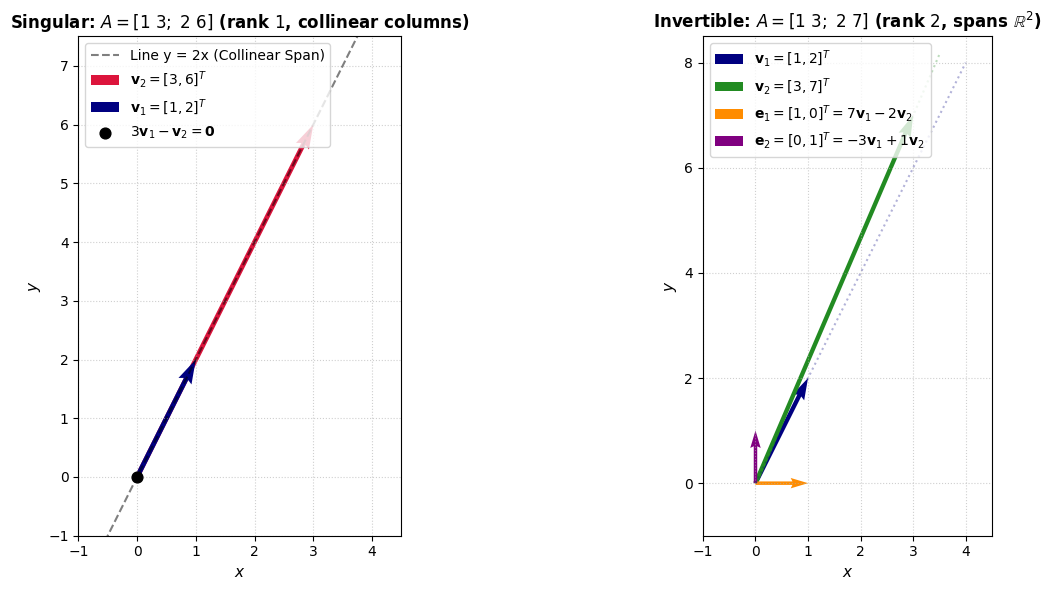

In [1]:
# Setup libraries
import numpy as np
import matplotlib.pyplot as plt

# Visualization 1: Collinear vs. Independent Column Vectors
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Singular Case
v1_sing = np.array([1, 2])
v2_sing = np.array([3, 6])

x_line = np.linspace(-1, 5, 100)
ax1.plot(x_line, 2 * x_line, 'k--', alpha=0.5, label='Line y = 2x (Collinear Span)')
ax1.quiver(0, 0, v2_sing[0], v2_sing[1], angles='xy', scale_units='xy', scale=1, color='crimson', width=0.015, label=r'$\mathbf{v}_2 = [3, 6]^T$')
ax1.quiver(0, 0, v1_sing[0], v1_sing[1], angles='xy', scale_units='xy', scale=1, color='navy', width=0.015, label=r'$\mathbf{v}_1 = [1, 2]^T$')

# Nullspace vector x = [3, -1]^T: 3*v1 - 1*v2 = 0
ax1.scatter([0], [0], color='black', zorder=5, s=60, label=r'$3\mathbf{v}_1 - \mathbf{v}_2 = \mathbf{0}$')
ax1.set_xlim(-1, 4.5)
ax1.set_ylim(-1, 7.5)
ax1.set_aspect('equal')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.set_title(r'Singular: $A=[1\ 3;\ 2\ 6]$ (rank $1$, collinear columns)', fontsize=12, fontweight='bold')
ax1.set_xlabel('$x$', fontsize=11)
ax1.set_ylabel('$y$', fontsize=11)
ax1.legend(loc='upper left')

# Invertible Case
v1_inv = np.array([1, 2])
v2_inv = np.array([3, 7])

ax2.quiver(0, 0, v1_inv[0], v1_inv[1], angles='xy', scale_units='xy', scale=1, color='navy', width=0.015, label=r'$\mathbf{v}_1 = [1, 2]^T$')
ax2.quiver(0, 0, v2_inv[0], v2_inv[1], angles='xy', scale_units='xy', scale=1, color='forestgreen', width=0.015, label=r'$\mathbf{v}_2 = [3, 7]^T$')
ax2.plot([0, 4], [0, 8], 'navy', linestyle=':', alpha=0.3)
ax2.plot([0, 3.5], [0, 8.16], 'forestgreen', linestyle=':', alpha=0.3)

# Basis vectors e1, e2 reached by combinations
ax2.quiver(0, 0, 1, 0, angles='xy', scale_units='xy', scale=1, color='darkorange', width=0.012, label=r'$\mathbf{e}_1 = [1, 0]^T = 7\mathbf{v}_1 - 2\mathbf{v}_2$')
ax2.quiver(0, 0, 0, 1, angles='xy', scale_units='xy', scale=1, color='purple', width=0.012, label=r'$\mathbf{e}_2 = [0, 1]^T = -3\mathbf{v}_1 + 1\mathbf{v}_2$')

ax2.set_xlim(-1, 4.5)
ax2.set_ylim(-1, 8.5)
ax2.set_aspect('equal')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.set_title(r'Invertible: $A=[1\ 3;\ 2\ 7]$ (rank $2$, spans $\mathbb{R}^2$)', fontsize=12, fontweight='bold')
ax2.set_xlabel('$x$', fontsize=11)
ax2.set_ylabel('$y$', fontsize=11)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()

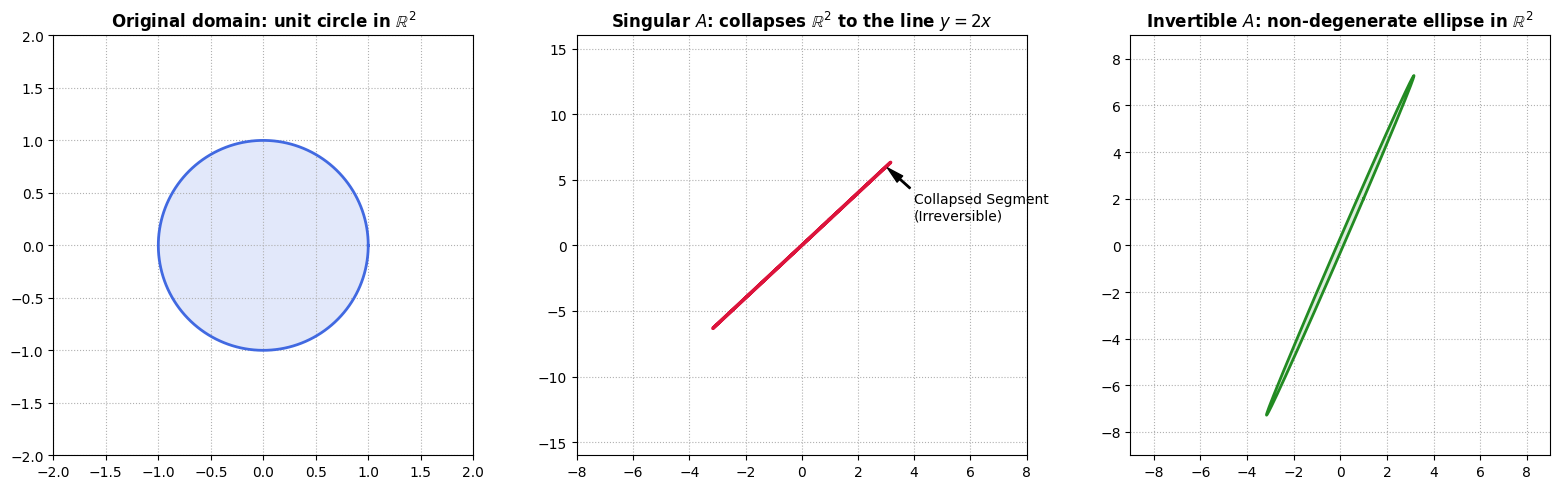

In [2]:
# Visualization 2: Geometric Transformation Mapping (Unit Circle Transformation)
theta = np.linspace(0, 2 * np.pi, 300)
unit_circle = np.array([np.cos(theta), np.sin(theta)])

A_singular = np.array([[1, 3], [2, 6]])
A_invertible = np.array([[1, 3], [2, 7]])

transformed_sing = A_singular @ unit_circle
transformed_inv = A_invertible @ unit_circle

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Original Circle
axes[0].plot(unit_circle[0], unit_circle[1], 'royalblue', lw=2)
axes[0].fill(unit_circle[0], unit_circle[1], 'royalblue', alpha=0.15)
axes[0].set_title(r'Original domain: unit circle in $\mathbb{R}^2$', fontweight='bold')
axes[0].set_xlim(-2, 2)
axes[0].set_ylim(-2, 2)
axes[0].set_aspect('equal')
axes[0].grid(True, linestyle=':')

# Under Singular Transformation
axes[1].plot(transformed_sing[0], transformed_sing[1], 'crimson', lw=2.5)
axes[1].set_title(r'Singular $A$: collapses $\mathbb{R}^2$ to the line $y=2x$', fontweight='bold')
axes[1].set_xlim(-8, 8)
axes[1].set_ylim(-16, 16)
axes[1].grid(True, linestyle=':')
axes[1].annotate('Collapsed Segment\n(Irreversible)', xy=(3, 6), xytext=(4, 2),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

# Under Invertible Transformation
axes[2].plot(transformed_inv[0], transformed_inv[1], 'forestgreen', lw=2)
axes[2].fill(transformed_inv[0], transformed_inv[1], 'forestgreen', alpha=0.15)
axes[2].set_title(r'Invertible $A$: non-degenerate ellipse in $\mathbb{R}^2$', fontweight='bold')
axes[2].set_xlim(-9, 9)
axes[2].set_ylim(-9, 9)
axes[2].set_aspect('equal')
axes[2].grid(True, linestyle=':')

plt.tight_layout()
plt.show()

In [3]:
# Verification 3: Robust Gauss-Jordan elimination with partial pivoting
import numpy as np

def gauss_jordan_invert(matrix, tol=None, verbose=True):
    """
    Compute the inverse of a square matrix using Gauss-Jordan elimination.

    Parameters
    ----------
    matrix : array-like
        A finite, square, numeric matrix.
    tol : float or None
        Absolute pivot tolerance. If None, a scale-aware default is used.
    verbose : bool
        If True, print the augmented matrix after each row operation.

    Returns
    -------
    numpy.ndarray
        The inverse of `matrix`.

    Notes
    -----
    Partial pivoting is used. A zero diagonal entry does not by itself
    imply singularity: rows are swapped to bring a suitable pivot into place.
    """
    try:
        A = np.asarray(matrix, dtype=float)
    except (TypeError, ValueError) as exc:
        raise TypeError("Input must be a rectangular numeric matrix.") from exc

    if A.ndim != 2:
        raise ValueError("Input must be a two-dimensional matrix.")
    rows, cols = A.shape
    if rows != cols:
        raise ValueError(f"Matrix must be square; received shape {A.shape}.")
    if rows == 0:
        raise ValueError("Matrix must not be empty.")
    if not np.all(np.isfinite(A)):
        raise ValueError("Matrix entries must all be finite numbers.")

    n = rows
    A_original = A.copy()
    scale = np.linalg.norm(A, ord=np.inf)
    if scale == 0:
        raise np.linalg.LinAlgError("Matrix is singular: all entries are zero.")

    if tol is None:
        pivot_tol = np.finfo(float).eps * max(1, n) * scale
    else:
        if not np.isscalar(tol) or not np.isfinite(tol) or tol < 0:
            raise ValueError("tol must be a finite, non-negative scalar.")
        pivot_tol = float(tol)

    aug = np.hstack((A.copy(), np.eye(n)))

    def show(message):
        if verbose:
            print(message)
            print(np.array2string(aug, precision=6, suppress_small=True))
            print("-" * 60)

    show("Initial augmented matrix [A | I]:")

    for col in range(n):
        # Partial pivoting: choose the largest available absolute pivot.
        pivot_row = col + int(np.argmax(np.abs(aug[col:, col])))
        pivot_value = aug[pivot_row, col]

        if abs(pivot_value) <= pivot_tol:
            raise np.linalg.LinAlgError(
                "Matrix is singular to the chosen numerical tolerance; "
                f"no usable pivot exists in column {col + 1}."
            )

        if pivot_row != col:
            aug[[col, pivot_row]] = aug[[pivot_row, col]]
            show(f"Swap R{col + 1} <-> R{pivot_row + 1}:")

        pivot_value = aug[col, col]
        aug[col] = aug[col] / pivot_value
        show(f"Normalize R{col + 1} by dividing by {pivot_value:.6g}:")

        for row in range(n):
            if row == col:
                continue
            factor = aug[row, col]
            if abs(factor) > pivot_tol:
                aug[row] -= factor * aug[col]
                show(f"R{row + 1} <- R{row + 1} - ({factor:.6g}) * R{col + 1}:")

    inverse = aug[:, n:]
    identity = np.eye(n)
    if not (np.allclose(A_original @ inverse, identity, rtol=1e-9, atol=1e-9)
            and np.allclose(inverse @ A_original, identity, rtol=1e-9, atol=1e-9)):
        raise np.linalg.LinAlgError("Computed inverse failed numerical identity checks.")

    if verbose:
        print("Computed inverse A^(-1):")
        print(np.array2string(inverse, precision=8, suppress_small=True))
        print("Verified: A @ A^(-1) ≈ I and A^(-1) @ A ≈ I")

    return inverse


# Example 1: the matrix used in the lecture notes.
A_test = np.array([[1, 3], [2, 7]], dtype=float)
A_inv_computed = gauss_jordan_invert(A_test)
print("\nCheck A @ A_inv:")
print(np.round(A_test @ A_inv_computed, decimals=8))
print("\nCheck A_inv @ A:")
print(np.round(A_inv_computed @ A_test, decimals=8))


# Example 2: an invertible matrix whose first diagonal pivot is zero.
A_swap_test = np.array([[0, 1], [1, 0]], dtype=float)
A_swap_inverse = gauss_jordan_invert(A_swap_test, verbose=True)
print("\nRow-swap test:")
print("Computed inverse:")
print(A_swap_inverse)
assert np.allclose(A_swap_inverse, np.linalg.inv(A_swap_test))


# Example 3: a singular matrix must be rejected.
A_singular_test = np.array([[1, 3], [2, 6]], dtype=float)
try:
    gauss_jordan_invert(A_singular_test, verbose=False)
except np.linalg.LinAlgError as error:
    print("\nExpected singular-matrix detection:")
    print(error)
else:
    raise AssertionError("A singular matrix was incorrectly accepted.")


# Example 4: a non-square matrix must be rejected clearly.
try:
    gauss_jordan_invert([[1, 2, 3], [4, 5, 6]], verbose=False)
except ValueError as error:
    print("\nExpected input-validation message:")
    print(error)
else:
    raise AssertionError("A non-square matrix was incorrectly accepted.")


Initial augmented matrix [A | I]:
[[1. 3. 1. 0.]
 [2. 7. 0. 1.]]
------------------------------------------------------------
Swap R1 <-> R2:
[[2. 7. 0. 1.]
 [1. 3. 1. 0.]]
------------------------------------------------------------
Normalize R1 by dividing by 2:
[[1.  3.5 0.  0.5]
 [1.  3.  1.  0. ]]
------------------------------------------------------------
R2 <- R2 - (1) * R1:
[[ 1.   3.5  0.   0.5]
 [ 0.  -0.5  1.  -0.5]]
------------------------------------------------------------
Normalize R2 by dividing by -0.5:
[[ 1.   3.5  0.   0.5]
 [-0.   1.  -2.   1. ]]
------------------------------------------------------------
R1 <- R1 - (3.5) * R2:
[[ 1.  0.  7. -3.]
 [-0.  1. -2.  1.]]
------------------------------------------------------------
Computed inverse A^(-1):
[[ 7. -3.]
 [-2.  1.]]
Verified: A @ A^(-1) ≈ I and A^(-1) @ A ≈ I

Check A @ A_inv:
[[1. 0.]
 [0. 1.]]

Check A_inv @ A:
[[1. 0.]
 [0. 1.]]
Initial augmented matrix [A | I]:
[[0. 1. 1. 0.]
 [1. 0. 0. 1.]]
----------